<a href="https://colab.research.google.com/github/202343500268-NaufalDaniswara/202343500268-Machine-Learning/blob/main/Latihan_BAB11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# --- KODE PERBAIKAN PRAKTIKUM 1 ---
print("=== Hasil Praktikum 1: PCA ===")
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

for n_comp in [0.80, 0.90, 0.95, None]:
    pca = PCA(n_components=n_comp) if n_comp else PCA()
    X_train_p = pca.fit_transform(X_train)
    X_test_p = pca.transform(X_test)
    model = LogisticRegression(max_iter=2000).fit(X_train_p, y_train)
    acc = accuracy_score(y_test, model.predict(X_test_p))

    # PERBAIKAN: Cek apakah n_comp adalah None sebelum melakukan format
    if n_comp is not None:
        print(f"n_components={n_comp:.2f} | dimensi={X_train_p.shape[1]}, akurasi={acc:.3f}")
    else:
        # Jika None, cetak tanpa format desimal
        print(f"n_components=None | dimensi={X_train_p.shape[1]}, akurasi={acc:.3f}")

=== Hasil Praktikum 1: PCA ===
n_components=0.80 | dimensi=5, akurasi=0.982
n_components=0.90 | dimensi=7, akurasi=0.982
n_components=0.95 | dimensi=10, akurasi=0.982
n_components=None | dimensi=30, akurasi=0.974



=== Hasil Praktikum 2: Perbandingan PCA, t-SNE, LDA ===


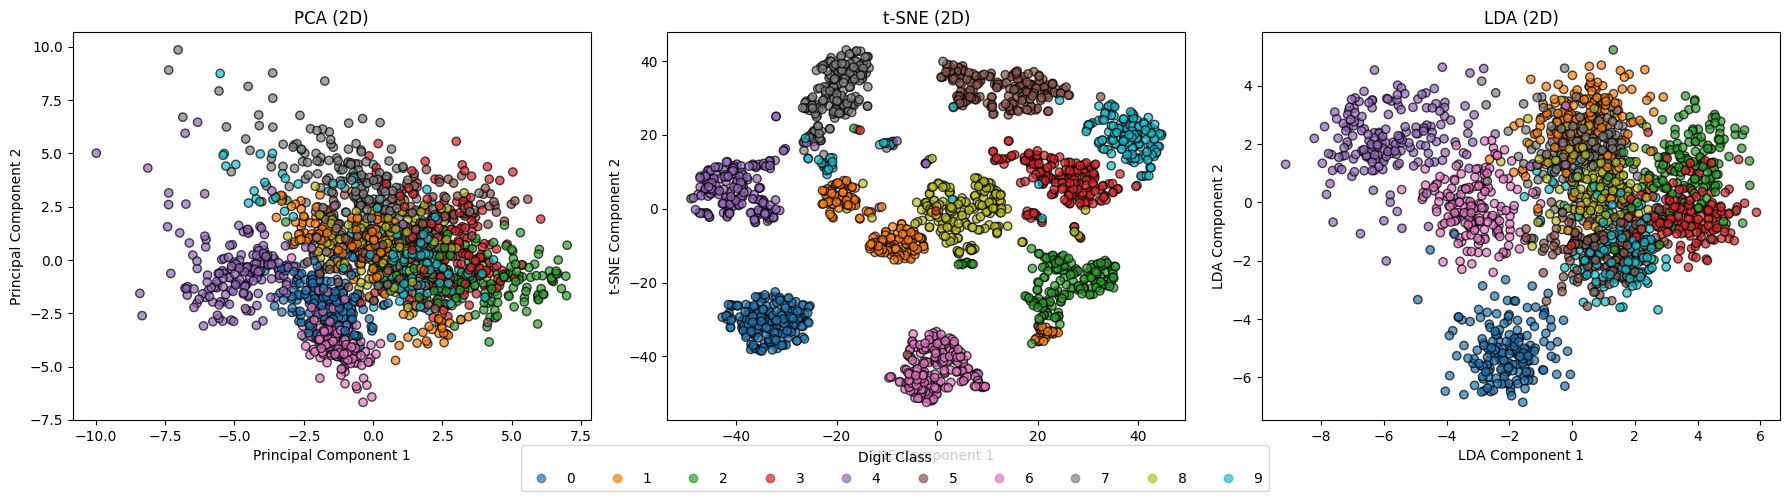


Analisis Kualitas Pemisahan Kelas:
1. PCA: Cenderung mengelompokkan data berdasarkan varians terbesar. Pemisahan kelas mungkin belum terlalu tegas (masih ada tumpang tindih).
2. t-SNE: Sangat baik dalam mempertahankan struktur lokal (neighborhood). Biasanya menghasilkan klaster yang sangat terpisah dan rapi untuk dataset digits.
3. LDA: Merupakan metode supervised (menggunakan label). Fokus pada memaksimalkan jarak antar kelas, sehingga pemisahan kelas biasanya sangat jelas dibandingkan PCA.


In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

print("\n=== Hasil Praktikum 2: Perbandingan PCA, t-SNE, LDA ===")

# 1. Load Dataset (Menggunakan Digits)
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

# Standarisasi data
X_digits_scaled = StandardScaler().fit_transform(X_digits)

# 2. Reduksi Dimensi ke 2 Komponen
# PCA
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_digits_scaled)

# t-SNE (Bisa memakan waktu beberapa detik)
tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_digits_scaled)

# LDA
lda = LDA(n_components=2)
X_lda = lda.fit_transform(X_digits_scaled, y_digits)

# 3. Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colormap = plt.cm.tab10 # Menggunakan colormap diskrit untuk kelas

# Plot PCA
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_digits, cmap=colormap, alpha=0.7, edgecolors='k')
axes[0].set_title('PCA (2D)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# Plot t-SNE
scatter2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_digits, cmap=colormap, alpha=0.7, edgecolors='k')
axes[1].set_title('t-SNE (2D)')
axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')

# Plot LDA
scatter3 = axes[2].scatter(X_lda[:, 0], X_lda[:, 1], c=y_digits, cmap=colormap, alpha=0.7, edgecolors='k')
axes[2].set_title('LDA (2D)')
axes[2].set_xlabel('LDA Component 1')
axes[2].set_ylabel('LDA Component 2')

# Menambahkan legend (opsional, karena kelas ada 0-9)
handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='lower center', ncol=10, title="Digit Class")

plt.tight_layout()
plt.subplots_adjust(bottom=0.15) # Memberi ruang untuk legend
plt.show()

print("\nAnalisis Kualitas Pemisahan Kelas:")
print("1. PCA: Cenderung mengelompokkan data berdasarkan varians terbesar. Pemisahan kelas mungkin belum terlalu tegas (masih ada tumpang tindih).")
print("2. t-SNE: Sangat baik dalam mempertahankan struktur lokal (neighborhood). Biasanya menghasilkan klaster yang sangat terpisah dan rapi untuk dataset digits.")
print("3. LDA: Merupakan metode supervised (menggunakan label). Fokus pada memaksimalkan jarak antar kelas, sehingga pemisahan kelas biasanya sangat jelas dibandingkan PCA.")